In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, RocCurveDisplay,
                             ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

TARGET = "Heart Attack Risk"
ID_COL = "Patient ID"

print("Train :", train.shape)
print("Test  :", test.shape)
print("Sample:", sample_sub.shape)

Train : (7010, 26)
Test  : (1753, 25)
Sample: (1753, 2)


In [3]:
display(train.head())
train.info()

,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Diet,Previous Heart Problems,Medication Use,Stress Level,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,RDG0550,33,Male,200,129/90,48,0,1,1,1,1,7.807690,Unhealthy,0,1,2,0.138443,184066,30.449815,63,6,7,Argentina,South America,Southern Hemisphere,1
1,NMA3851,56,Female,262,159/105,46,1,0,1,0,0,17.297628,Average,1,0,8,0.369552,211755,34.973685,333,7,8,Nigeria,Africa,Northern Hemisphere,1
2,TUI5807,19,Female,140,161/109,54,0,1,0,0,1,8.695288,Average,1,1,3,8.646334,252203,30.554246,537,2,10,Thailand,Asia,Northern Hemisphere,0
3,YYT5016,50,Female,163,120/62,53,0,1,1,1,1,10.161587,Healthy,0,1,7,1.107884,121954,35.390265,591,0,9,Spain,Europe,Southern Hemisphere,1
4,ZAC5937,89,Female,144,153/110,92,1,0,1,0,1,16.436787,Healthy,1,0,1,1.337570,180121,39.575483,145,2,5,Germany,Europe,Northern Hemisphere,1


<class 'pandas.DataFrame'>
RangeIndex: 7010 entries, 0 to 7009
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Patient ID                       7010 non-null   str    
 1   Age                              7010 non-null   int64  
 2   Sex                              7010 non-null   str    
 3   Cholesterol                      7010 non-null   int64  
 4   Blood Pressure                   7010 non-null   str    
 5   Heart Rate                       7010 non-null   int64  
 6   Diabetes                         7010 non-null   int64  
 7   Family History                   7010 non-null   int64  
 8   Smoking                          7010 non-null   int64  
 9   Obesity                          7010 non-null   int64  
 10  Alcohol Consumption              7010 non-null   int64  
 11  Exercise Hours Per Week          7010 non-null   float64
 12  Diet                           

In [4]:
print("Total missing value:", train.isna().sum().sum())
print("Duplikat baris     :", train.duplicated().sum())
print("Duplikat ID        :", train[ID_COL].duplicated().sum())
print("ID train & test tumpang tindih:", len(set(train[ID_COL]) & set(test[ID_COL])))

display(train.describe().T.round(2))

for col in ["Sex", "Diet", "Continent", "Hemisphere"]:
    print(col, train[col].value_counts().to_dict())
print("Jumlah Country:", train["Country"].nunique())

Total missing value: 0
Duplikat baris     : 0
Duplikat ID        : 0
ID train & test tumpang tindih: 0


,count,mean,std,min,25%,50%,75%,max
Age,7010.0,53.51,21.29,18.0,35.00,53.00,72.00,90.00
Cholesterol,7010.0,259.88,80.71,120.0,192.00,259.00,329.00,400.00
Heart Rate,7010.0,75.11,20.51,40.0,57.00,75.00,93.00,110.00
Diabetes,7010.0,0.65,0.48,0.0,0.00,1.00,1.00,1.00
Family History,7010.0,0.49,0.50,0.0,0.00,0.00,1.00,1.00
Smoking,7010.0,0.90,0.30,0.0,1.00,1.00,1.00,1.00
Obesity,7010.0,0.50,0.50,0.0,0.00,0.00,1.00,1.00
Alcohol Consumption,7010.0,0.60,0.49,0.0,0.00,1.00,1.00,1.00
Exercise Hours Per Week,7010.0,9.98,5.77,0.0,5.05,9.98,15.03,20.00
Previous Heart Problems,7010.0,0.50,0.50,0.0,0.00,0.00,1.00,1.00


Sex {'Male': 4891, 'Female': 2119}
Diet {'Healthy': 2351, 'Average': 2341, 'Unhealthy': 2318}
Continent {'Asia': 2028, 'Europe': 1788, 'South America': 1100, 'Australia': 714, 'Africa': 702, 'North America': 678}
Hemisphere {'Northern Hemisphere': 4526, 'Southern Hemisphere': 2484}
Jumlah Country: 20


Heart Attack Risk
0    4506
1    2504
Name: count, dtype: int64
Heart Attack Risk
0    0.6428
1    0.3572
Name: proportion, dtype: float64


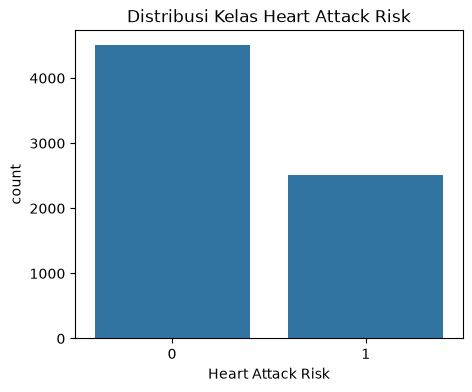

In [5]:
print(train[TARGET].value_counts())
print(train[TARGET].value_counts(normalize=True).round(4))

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=train)
plt.title("Distribusi Kelas Heart Attack Risk")
plt.show()

In [6]:
def buat_fitur(df):
    df = df.copy()
    bp = df["Blood Pressure"].str.split("/", expand=True).astype(float)
    df["Systolic"] = bp[0]
    df["Diastolic"] = bp[1]
    return df.drop(columns=[ID_COL, "Blood Pressure"])

X = buat_fitur(train.drop(columns=TARGET))
y = train[TARGET]
X_test = buat_fitur(test)[X.columns]   # urutan kolom sama dengan train

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerik    :", len(num_cols))
print("Kategorikal:", cat_cols)

Numerik    : 20
Kategorikal: ['Sex', 'Diet', 'Country', 'Continent', 'Hemisphere']


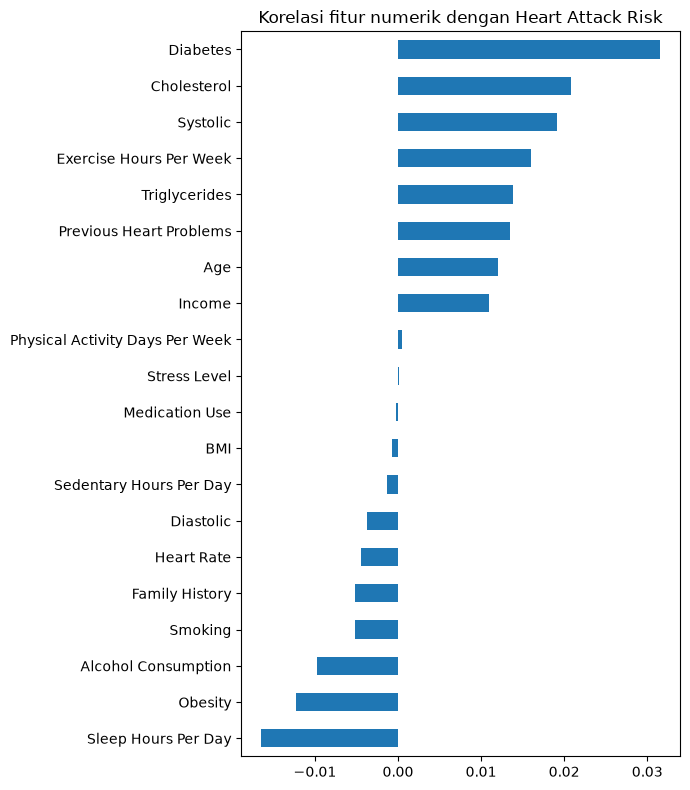

,rasio_risiko,jumlah
Sex,,
Female,0.355,2119
Male,0.358,4891


,rasio_risiko,jumlah
Diet,,
Average,0.345,2341
Healthy,0.364,2351
Unhealthy,0.362,2318


,rasio_risiko,jumlah
Hemisphere,,
Northern Hemisphere,0.359,4526
Southern Hemisphere,0.355,2484


,rasio_risiko,jumlah
Continent,,
Africa,0.366,702
Asia,0.347,2028
Australia,0.364,714
Europe,0.343,1788
North America,0.382,678
South America,0.373,1100


In [7]:
# Korelasi fitur numerik dengan target
corr = X[num_cols].assign(target=y).corr()["target"].drop("target").sort_values()
plt.figure(figsize=(7, 8))
corr.plot(kind="barh")
plt.title("Korelasi fitur numerik dengan Heart Attack Risk")
plt.tight_layout()
plt.show()

# Rasio target per kategori
for col in ["Sex", "Diet", "Hemisphere", "Continent"]:
    display(X.assign(target=y).groupby(col)["target"].agg(["mean", "count"]).round(3)
            .rename(columns={"mean": "rasio_risiko", "count": "jumlah"}))

In [8]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Validasi:", X_val.shape)

Train: (5608, 25) | Validasi: (1402, 25)


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "accuracy", "f1", "precision", "recall"]

rows = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    hasil = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("roc_auc", ascending=False)
display(hasil_cv)
print("Accuracy jika menebak semua 0:", round((y_train == 0).mean(), 4))

,roc_auc,accuracy,f1,precision,recall
Model,,,,,
Decision Tree,0.5094,0.5708,0.3168,0.3697,0.2910
Gradient Boosting,0.5059,0.6320,0.0549,0.3296,0.0300
Random Forest,0.5022,0.5733,0.2811,0.3528,0.2336
Logistic Regression,0.4948,0.4977,0.4083,0.3524,0.4853


Accuracy jika menebak semua 0: 0.6428


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.5806,0.3636,0.2315,0.2829,0.5196
Logistic Regression,0.5093,0.3696,0.5289,0.4351,0.5158
Gradient Boosting,0.6305,0.2258,0.0140,0.0263,0.5098
Decision Tree,0.5856,0.3630,0.2116,0.2673,0.4974


Model terbaik: Random Forest
                   precision    recall  f1-score   support

Risiko rendah (0)       0.64      0.77      0.70       901
Risiko tinggi (1)       0.36      0.23      0.28       501

         accuracy                           0.58      1402
        macro avg       0.50      0.50      0.49      1402
     weighted avg       0.54      0.58      0.55      1402



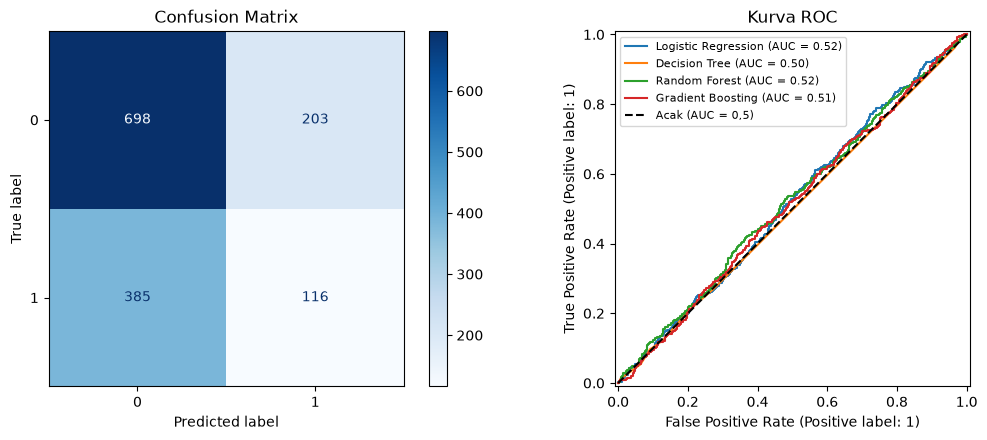

In [10]:
fitted, rows = {}, []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    proba = pipe.predict_proba(X_val)[:, 1]
    fitted[nama] = pipe
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, proba),
    })

hasil_val = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC-AUC", ascending=False)
display(hasil_val)

nama_terbaik = hasil_val.index[0]
pred = fitted[nama_terbaik].predict(X_val)
print("Model terbaik:", nama_terbaik)
print(classification_report(y_val, pred, target_names=["Risiko rendah (0)", "Risiko tinggi (1)"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val, pred, cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
for nama, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_val, y_val, name=nama, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Acak (AUC = 0,5)")
axes[1].set_title("Kurva ROC")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

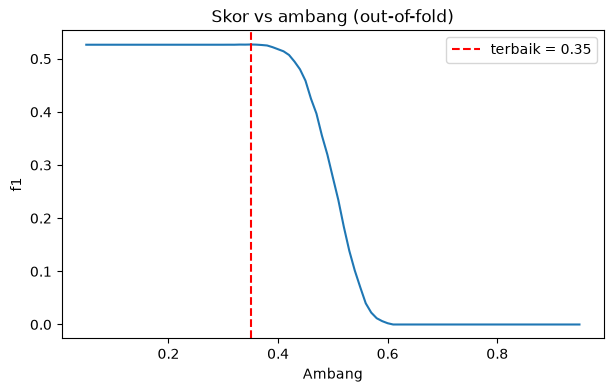

Ambang terbaik: 0.35 | f1 = 0.5268
Pembanding tebak semua 1 : 0.5264
Pembanding tebak semua 0 : 


In [11]:
# Ganti METRIK sesuai ketentuan tugas: "f1" atau "accuracy"
METRIK = "f1"

pipe_final = Pipeline([("prep", preprocess), ("clf", models[nama_terbaik])])

# Probabilitas out-of-fold pada seluruh data train (bukan data test)
oof = cross_val_predict(pipe_final, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

ambang = np.linspace(0.05, 0.95, 91)
skor = [f1_score(y, oof >= t) if METRIK == "f1" else accuracy_score(y, oof >= t) for t in ambang]
t_terbaik = ambang[int(np.argmax(skor))]

plt.figure(figsize=(7, 4))
plt.plot(ambang, skor)
plt.axvline(t_terbaik, color="r", ls="--", label=f"terbaik = {t_terbaik:.2f}")
plt.xlabel("Ambang"); plt.ylabel(METRIK); plt.legend(); plt.title("Skor vs ambang (out-of-fold)")
plt.show()

print(f"Ambang terbaik: {t_terbaik:.2f} | {METRIK} = {max(skor):.4f}")
print("Pembanding tebak semua 1 :", round(f1_score(y, np.ones(len(y))), 4) if METRIK == "f1" else "")
print("Pembanding tebak semua 0 :", round(accuracy_score(y, np.zeros(len(y))), 4) if METRIK == "accuracy" else "")

In [12]:
pipe_final.fit(X, y)
proba_test = pipe_final.predict_proba(X_test)[:, 1]
label_test = (proba_test >= t_terbaik).astype(int)

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: label_test})
submission = sample_sub[[ID_COL]].merge(submission, on=ID_COL, how="left")   # samakan urutan

assert submission.shape == sample_sub.shape
assert submission[TARGET].notna().all()

submission.to_csv("submission_heart.csv", index=False)
display(submission.head())
print(submission[TARGET].value_counts(normalize=True).round(3))
print("Tersimpan: submission_heart.csv")

,Patient ID,Heart Attack Risk
0,BMW7812,1
1,XXM0972,1
2,RQX1211,1
3,RVN4963,0
4,NCU1956,1


Heart Attack Risk
1    0.994
0    0.006
Name: proportion, dtype: float64
Tersimpan: submission_heart.csv


# README: Dataset Heart Attack Risk

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `train.csv`, `test.csv`, `sample_submission.csv` |
| Jumlah data | Train 7.010 baris, test 1.753 baris |
| Kolom train | 26 kolom: 1 ID (`Patient ID`), 24 fitur, 1 target (`Heart Attack Risk`) |
| Tipe fitur | Numerik (misalnya `Age`, `Cholesterol`, `BMI`), biner 0/1 (misalnya `Diabetes`, `Smoking`), kategorikal (`Sex`, `Diet`, `Country`, `Continent`, `Hemisphere`), dan `Blood Pressure` berbentuk teks `sistolik/diastolik` |
| Target | `Heart Attack Risk` |
| Missing value | Tidak ada |
| Duplikat | Tidak ada |

Dataset ini berisi data kesehatan dan gaya hidup pasien beserta label risiko serangan jantung.

## Mengapa ini termasuk klasifikasi biner

1. **Pembelajaran terawasi (supervised).** Setiap pasien pada data train sudah punya label `Heart Attack Risk`.
2. **Targetnya kategorikal.** `Heart Attack Risk` adalah label kelas, bukan nilai kontinu seperti kadar kolesterol. Karena itu masalahnya bukan regresi.
3. **Targetnya hanya punya tepat dua nilai.**

| Nilai `Heart Attack Risk` | Arti | Jumlah (train) | Persentase |
|---|---|---|---|
| 0 | Risiko rendah (tidak berisiko) | 4.506 | 64,3% |
| 1 | Risiko tinggi (berisiko) | 2.504 | 35,7% |

4. **Kedua kelas saling lepas.** Satu pasien hanya masuk ke salah satu kelas, tanpa kelas ketiga.
5. **Format submission memperkuat hal ini.** `sample_submission.csv` berisi label **0/1**, jadi keluaran yang diminta adalah kelas prediksi.

## Karakteristik penting

- **Kelas cukup tidak seimbang** (sekitar 64:36). Bandingkan skor model dengan baseline menebak semua 0 (akurasi 0,643).
- **Feature engineering:** `Blood Pressure` dipecah menjadi `Systolic` dan `Diastolic`. `Patient ID` dibuang.
- Karena label submission berupa 0/1, pilihan ambang (threshold) memengaruhi skor, terutama bila metriknya F1.

## Hasil baseline (5-fold cross-validation)

| Model | ROC-AUC | Accuracy | F1 |
|---|---|---|---|
| Logistic Regression | 0,498 | 0,499 | 0,413 |
| Random Forest | 0,499 | 0,579 | 0,277 |
| Gradient Boosting | 0,506 | 0,636 | 0,040 |

ROC-AUC sekitar 0,5 berarti model tidak lebih baik dari tebakan acak, dan akurasi terbaik (0,636) masih di bawah menebak semua 0 (0,643). Korelasi tertinggi fitur dengan target hanya 0,032 (`Diabetes`). Artinya, fitur pada dataset ini hampir tidak membawa informasi untuk memprediksi `Heart Attack Risk`. Temuan ini adalah sifat datanya, bukan kesalahan kode.